In [43]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [44]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [45]:
train_folder = ("/kaggle/input/datasets/nabiladib14/epic-and-cscr-hospital-dataset/Epic and CSCR hospital Dataset/Train")
test_folder = ("/kaggle/input/datasets/nabiladib14/epic-and-cscr-hospital-dataset/Epic and CSCR hospital Dataset/Test")

In [46]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

train_data = datasets.ImageFolder(train_folder, transform = train_transform)
test_data = datasets.ImageFolder(test_folder, transform = test_transform)

print("Train:", len(train_data), "Test:", len(test_data))

Train: 9650 Test: 2414


In [47]:
batch_size = 32
epochs = 15
learning_rate = 0.001

In [48]:
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

In [49]:
class CNNModel(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 30, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(30, 50, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(50, 60, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(60 * 8 * 8, 500),
            nn.ReLU(),
            nn.Linear(500, 250),
            nn.ReLU(),
            nn.Linear(250, num_classes),
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

model = CNNModel(num_classes=len(class_names)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

In [50]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [51]:
train_losses = []
train_accuracies = []

for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")

Epoch 1/15 | Train Loss: 0.8216 | Train Accuracy: 0.6646
Epoch 2/15 | Train Loss: 0.4890 | Train Accuracy: 0.8121
Epoch 3/15 | Train Loss: 0.3506 | Train Accuracy: 0.8666
Epoch 4/15 | Train Loss: 0.2687 | Train Accuracy: 0.8988
Epoch 5/15 | Train Loss: 0.2035 | Train Accuracy: 0.9251
Epoch 6/15 | Train Loss: 0.1687 | Train Accuracy: 0.9376
Epoch 7/15 | Train Loss: 0.1271 | Train Accuracy: 0.9547
Epoch 8/15 | Train Loss: 0.1077 | Train Accuracy: 0.9633
Epoch 9/15 | Train Loss: 0.1013 | Train Accuracy: 0.9649
Epoch 10/15 | Train Loss: 0.0794 | Train Accuracy: 0.9716
Epoch 11/15 | Train Loss: 0.0799 | Train Accuracy: 0.9718
Epoch 12/15 | Train Loss: 0.0592 | Train Accuracy: 0.9799
Epoch 13/15 | Train Loss: 0.0615 | Train Accuracy: 0.9806
Epoch 14/15 | Train Loss: 0.0483 | Train Accuracy: 0.9847
Epoch 15/15 | Train Loss: 0.0432 | Train Accuracy: 0.9860


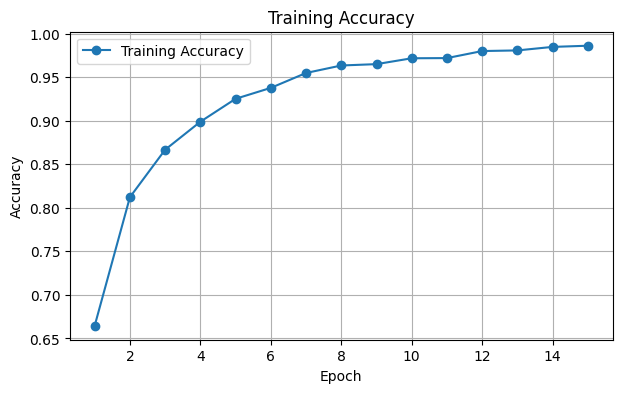

In [52]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), train_accuracies, marker="o", label="Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [53]:
model.eval()
correct, total = 0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        preds = model(images).argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_accuracy = correct / total
print(f"Final Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

Final Test Accuracy: 0.9453 (94.53%)
